# Passive Radar Project

* A transmitter sending a known signal $s(t)$
* A reference channel receives the signal
* A vigilance signal receives an echo reflected by a target

Let the received signal be $R(t)$. The signal received at the vigilance channel $V(t)$ can be defined as $$V(t) = \alpha e^{i \phi} R(t-e)$$ where:
* \alpha is the ratio between the echo amplitude and the reference amplitude
* \phi is the phase difference
* $e$ is the time delay between the $R(t)$ reception and $V(t)$ reception

We can use the correlation $C$ between $V(t)$ and $R(t)$ to align and "measure" the similarity between them. 
$$C(\tau) = \int V(t) R^* (t-\tau) dt$$
By definition of $V(t)$:
$$C(\tau) = \alpha e^{i\phi} \int R(t-e) R^{*}(t-\tau) dt$$

if  $\tau = e$, $$ C(e) = \alpha e^{i\phi} \int \|R(t-e)\|^{2} dt = \alpha e^{i\phi} E_{R} $$ 

where $E_{R}$ is the reference energy. The discrete version: $E_R = \sum_{k}|R[k]|^2 $ 

The estimated delay $\hat{e}$ is defined as $$\hat{e} = \argmax_{\tau} \| C(\tau)\|$$

Then we can estimate $$\hat{\beta} = \cfrac{C{e}}{E_R}$$
In an ideal scenario $\hat{\beta} = \alpha e^{i\phi}$
Resulting in the estimators:$$ \hat{\alpha} = \| \beta\| =  \cfrac{\| C(\hat{e})\|}{E_r}$$ and $$\hat{\phi} = \arg C(\hat{e})$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
size = 128
d = 20
alpha = 0.2
phi = np.pi/3

R = np.random.choice([-1,1], size = size)

V = (alpha * np.exp(1j * phi))*np.append(np.zeros(d), R)
C = np.correlate(V, R, mode = 'full')


e = np.argmax(np.abs(C)) - (len(R) -1)
e2 = np.argmax(np.abs(C)) - (len(R) -1)
print(f"Estimated delay: {e}, Actual delay: {d}")
print(f"Estimated delay: {e2}, Actual delay: {d}")

max_C, idx_C = np.max(np.abs(C)), np.argmax(np.abs(C))
alpha_hat = max_C / np.sum(np.abs(R)**2)
phi_hat = np.arctan2(C[idx_C].imag, C[idx_C].real)

print(f"Estimated amplitude: {alpha_hat}")
print(f"Estimated phase: {phi_hat}")

Estimated delay: 20, Actual delay: 20
Estimated delay: 20, Actual delay: 20
Estimated amplitude: 0.19999999999999998
Estimated phase: 1.0471975511965974


Text(0, 0.5, 'Magnitude')

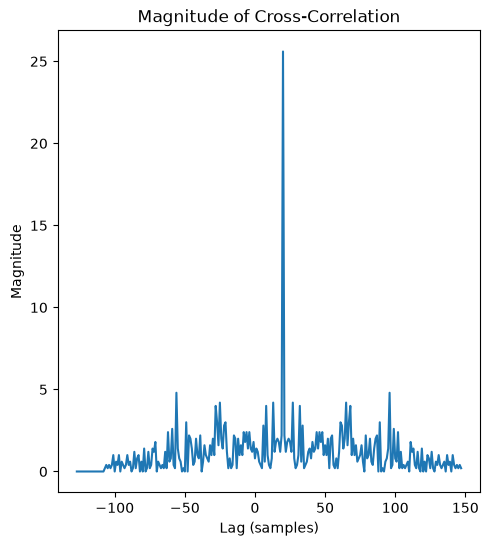

In [3]:
lag = np.arange(len(C)) - len(R) + 1
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(lag, np.abs(C))
plt.title('Magnitude of Cross-Correlation')
plt.xlabel('Lag (samples)')
plt.ylabel('Magnitude') 